# ETF-hedged residual reversion: pre-registered research pipeline (Holdout Research, strategy 03)

**H1 (primary).** For large US stocks, the daily residual versus the sector ETF (beta-adjusted, no intercept) negatively predicts the next-day residual; an ETF-hedged, dollar-neutral reversal book earns a positive net Sharpe in the holdout.
**Pre-registered prior:** a detectable gross effect that does not survive costs ("gross-only"). A null result is a valid result.

The notebook imports everything from `src/` and narrates the stages. Holdout (2024-01-01 to 2026-09-30) results appear only after `scripts/run_stage3_holdout.py --confirm` has been run once; this notebook never runs it.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, Image, display
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / 'scripts'))
from src.config import load_config, RESULTS_DIR, PROC_DIR, RAW_DIR
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 70)
cfg = load_config()
RERUN_STAGE0 = not (RAW_DIR / 'prices_raw.parquet').exists()   # raw data is cached; only re-download if missing
RERUN_STAGE1 = False                                             # ~2 minutes with multiprocessing
RERUN_STAGE2 = True
pd.Series({k: cfg[k] for k in ['etfs','benchmark','dates','split','filters','signal','timing','costs','inference']}).to_frame('pre-registered config')

,pre-registered config
etfs,"[XLK, XLF, XLE, XLV, XLY, XLP, XLI, XLB, XLU, XLRE, XLC]"
benchmark,SPY
dates,"{'data_start': '2018-06-01', 'signal_start': '2018-10-01', 'end': ..."
split,"{'in_sample': ['2018-10-01', '2023-12-31'], 'holdout': ['2024-01-0..."
filters,{'min_price': 5.0}
signal,"{'beta_window': 60, 'min_beta_obs': 50, 'z_window': 60, 'min_z_obs..."
timing,"{'primary': 'open_open', 'variants': ['close_close_lag', 'same_clo..."
costs,"{'stock_bps_per_side': 5.0, 'etf_bps_per_side': 1.0, 'borrow_bps_p..."
inference,"{'nw_lags': 5, 'bootstrap_mean_block': 10, 'bootstrap_resamples': ..."


## Stage 0: data
Yahoo prices (`auto_adjust=False`) and Wikipedia constituents; point-in-time S&P 500 membership rebuilt backwards from the current list. Raw prices are split at download into in-sample and holdout files; everything below reads the in-sample file only.

In [2]:
if RERUN_STAGE0:
    import run_stage0_data; run_stage0_data.main()
display(Markdown((RESULTS_DIR / 'data_quality.md').read_text()[:6000]))

# Data quality & coverage (Stage 0)

Generated by `scripts/run_stage0_data.py`. Diagnostics cover **2018-06-01 to 2023-12-31 only**; holdout-period prices were split off at download and were not inspected (holdout checks run in Stage 3).

## Sources and conventions

- Prices: Yahoo Finance via `yfinance` (`auto_adjust=False`). `Close` is **split-adjusted but not dividend-adjusted** (true as-traded prices are not available from Yahoo); the $5 filter uses it, so stocks that later split may look cheaper than they were at the time. Returns use `Adj Close`; open-to-open uses `adj_open = Open*AdjClose/Close`.
- Universe: current S&P 500 list from Wikipedia (503 tickers) rolled back with the additions/removals table (https://en.wikipedia.org/wiki/Historical_components_of_the_S%26P_500; the table now lives on the 'Historical components' page, see DEVIATIONS.md). A change takes effect for the session on its effective date.
- Risk-free series for benchmark excess returns: `^IRX` (Yahoo 13-week T-bill yield).

## Survivorship bias

Survivorship bias is **reduced, not eliminated**. Removed stocks (acquired, bankrupt, shrunk) are far less likely than survivors to have Yahoo price history or a Yahoo sector label, so the usable universe is tilted towards survivors. The coverage table below quantifies this by year.

## Coverage by calendar year (average over sessions)

| year | (a) PIT members | (b) with price data | (c) with sector label | (d) usable for trading | flag |
|---|---|---|---|---|---|
| 2018 | 508.0 | 86.0% | 87.6% | 86.0% | **<90%** |
| 2019 | 506.4 | 88.0% | 89.2% | 88.0% | **<90%** |
| 2020 | 506.0 | 90.3% | 91.1% | 90.3% |  |
| 2021 | 506.0 | 91.8% | 92.6% | 91.8% |  |
| 2022 | 504.7 | 93.8% | 94.7% | 93.8% |  |
| 2023 | 504.0 | 95.6% | 96.5% | 95.6% |  |
| 2024 | 504.0 | deferred to Stage 3 | 97.3% | deferred to Stage 3 |  |
| 2025 | 504.0 | deferred to Stage 3 | 98.3% | deferred to Stage 3 |  |
| 2026 | 504.0 | deferred to Stage 3 | 99.6% | deferred to Stage 3 |  |

(b) and (d) for holdout years need holdout prices and are filled in by Stage 3.

## Excluded / problem tickers (point-in-time members during the in-sample window)

- Members in-sample: **613** tickers. With price data: 532. No downloadable prices (excluded, logged): **81**. Priced but no usable sector label (excluded): **0**.
- Full list: `data/processed/ticker_status.csv`; sector sources/mapping: `data/processed/sector_map.csv`, `yahoo_to_gics_mapping.csv`.
- Of the 157 in-sample members that are no longer in the index, 76 are usable (48%), versus 100% of survivors.

No-price tickers:

ABMD, ADS, AET, AGN, ALXN, ANDV, ANSS, APC, ARNC, ATVI, AVB, BMS, CA, CDAY, CELG, CERN, CMA, COL, CTLT, CTRA, CTXS, CXO, DFS, DISCA, DISCK, DISH, DPS, DRE, DWDP, EA, ESRX, ETFC, EVHC, FBHS, FL, FLIR, FLT, FRC, GGP, GPS, HBI, HES, HFC, HOLX, INFO, IPG, JNPR, JWN, K, KSU, LEG, LLL, MON, MRO, MXIM, NBL, NFX, NLSN, PBCT, PXD, QRVO, RHT, RTN, SBNY, SCG, SEE, SIVB, SRCL, TIF, TSS, TWTR, TWX, VAR, VIAB, WBA, WBD, WCG, WLTW, XEC, XL, XLNX

Priced but excluded for sector:

none

## Membership reconstruction issues (5)

Logged, not silently fixed. See `results/membership_reconstruction_issues.csv`.

| date                | ticker   | issue                                       | row                                                                |
|:--------------------|:---------|:--------------------------------------------|:-------------------------------------------------------------------|
| 2026-03-23 00:00:00 | SATS     | undo-add: ticker not in membership          | Market capitalization changes.                                     |
| 2022-04-11 00:00:00 | WBD      | undo-add: ticker not in membership          | WarnerMedia and Discovery merged to create Warner Bros. Discovery. |
| 2022-01-10 00:00:00 | WTW      | possible symbol change (same security name) | Willis Towers Watson changed its ticker symbol from WLTW to WTW.   |
| 2019-06-03 00:00:00 | DD       | possible symbol change (same security name) | DWDP changed to DD after spinning off Corteva.                     |
| 2018-06-20 00:00:00 | FLT      | undo-add: ticker not in membership          | AT&T acquired Time Warner.                                         |

## Price checks (in-sample window)

- Duplicate (ticker,date) rows: **0**.
- Tickers with NaN/zero/negative OHLC rows: **0** (total rows 0). `results/dq_nan_or_nonpositive_prices.csv`.
- Tickers with missing NYSE sessions inside their price history, or dates that are not NYSE sessions: **0**. `results/dq_missing_sessions.csv`.
  - ETFs/benchmark among them: none.
- Single-day |Adj Close return| > 50%: **11** rows (0 coincide with a split flag). `results/dq_moves_gt_50pct.csv`. Nothing was removed or winsorised; flagged observations are used as downloaded.

ticker       date       ret     Close  Adj Close  Stock Splits  split_same_day
   APA 2020-03-09 -0.538647  9.550000   8.071707           0.0           False
  CPRI 2023-08-10  0.557353 53.900002  53.900002           0.0           False
  CVNA 2023-06-08  0.560206  4.846000   4.846000           0.0           False
   FLR 2020-03-19  0.761765  5.990000   5.990000           0.0           False
  HOOD 2021-08-04  0.504060 70.389999  70.389999           0.0           False
  NKTR 2022-03-14 -0.608655 62.400002  62.400002           0.0           False
  NKTR 2023-08-07  0.924528 15.300000  15.300000           0.0           False
   OXY 2020-03-09 -0.520138 12.510000  11.601177           0.0           False
   PCG 2019-01-14 -0.523593  8.380000   8.202487           0.0           False
   PCG 2019-01-24  0.745933 13.950000  13.654500           0.0           False
  TRGP 2020-03-09 -0.529074 13.120000  11.473202           0.0           False


## Stage 1: simulation validation (must pass before any real signal is computed)

In [3]:
if RERUN_STAGE1:
    import run_stage1_sims; run_stage1_sims.main()
display(pd.read_csv(RESULTS_DIR / 'stage1_checks.csv'))
print(json.loads((RESULTS_DIR / 'stage1_extra.json').read_text()))
pd.read_csv(RESULTS_DIR / 'stage1_placebo.csv').describe().loc[['mean','50%','min','max']].round(3)

,check,value,passed
0,1a planted: mean FM coef within +/-0.02 of -0.10,-0.0984,True
1,1a planted: mean gross daily return > 0,1.43e-03 (positive in 100% of sims),True
2,1b null: share of sims with FM |t|>2 <= 10%,3.0%,True
3,1b null: share of sims with net-Sharpe CI entirely above 0 <= 10%,0.0%,True
4,"1c placebo (real in-sample data, wrong-ETF hedge): share of shuffl...","0% (median FM t=-1.40, median net Sharpe=-1.60)",True
5,1d unit tests (incl. look-ahead tests),13 passed in 2.96s,True


{'null_gross_ci_above_zero': 0.025, 'null_mean_fm': -1.3474078484412527e-05, 'planted_mean_gross_sharpe': 20.192783601688937, 'planted_mean_net_sharpe': 7.386028103488459, 'planted_gross_ci_above_zero': 1.0, 'planted_fm_sd': 0.0015639622228756063}


,shuffle,fm_coef,fm_t,gross_sharpe,net_sharpe,gross_ci_lo,gross_ci_hi,net_ci_lo,net_ci_hi
mean,9.5,-0.008,-1.372,0.813,-1.581,-0.086,1.753,-2.501,-0.687
50%,9.5,-0.008,-1.403,0.803,-1.598,-0.097,1.745,-2.518,-0.689
min,0.0,-0.009,-1.600,0.727,-1.642,-0.148,1.644,-2.586,-0.774
max,19.0,-0.007,-1.191,1.046,-1.403,0.140,2.036,-2.349,-0.481


## Stage 2: in-sample (2018-10-01 to 2023-12-31, by P&L exit date)
No parameter is changed on the basis of these results.

In [4]:
from src.market import load_market_data
from src.report_tables import Period, run_report
if RERUN_STAGE2:
    md, rf = load_market_data(cfg, include_holdout=False)
    a, b = cfg['split']['in_sample']
    res = run_report(md, rf, cfg, Period('in_sample', pd.Timestamp(a), pd.Timestamp(b)), 'is')
tabs = pd.read_csv(RESULTS_DIR / 'is_strategy_tables.csv')
cols = ['strategy','cost_scenario','ann_return','ann_vol','sharpe','sharpe_ci_lo','sharpe_ci_hi','max_drawdown','turnover_daily','avg_long','avg_short','hit_rate','breakeven_bps_per_side','beta_spy','alpha_ann','alpha_nw_t']
tabs[tabs.group.isin(['primary','variants'])][cols].round(3)

,strategy,cost_scenario,ann_return,ann_vol,sharpe,sharpe_ci_lo,sharpe_ci_hi,max_drawdown,turnover_daily,avg_long,avg_short,hit_rate,breakeven_bps_per_side,beta_spy,alpha_ann,alpha_nw_t
0,"PRIMARY open_open, sector-ETF hedge, |z|>=1, 1-day hold",gross,0.024,0.069,0.346,-0.480,1.196,-0.123,1.730,56.735,57.939,0.531,0.185,0.045,0.018,0.636
1,"PRIMARY open_open, sector-ETF hedge, |z|>=1, 1-day hold",net_2bps,-0.079,0.069,-1.149,-2.004,-0.346,-0.390,1.730,56.735,57.939,0.470,0.185,0.045,-0.085,-3.048
2,"PRIMARY open_open, sector-ETF hedge, |z|>=1, 1-day hold",net_5bps,-0.210,0.069,-3.047,-4.067,-2.150,-0.674,1.730,56.735,57.939,0.382,0.185,0.045,-0.216,-7.778
3,"PRIMARY open_open, sector-ETF hedge, |z|>=1, 1-day hold",net_10bps,-0.428,0.069,-6.204,-7.701,-4.976,-0.895,1.730,56.735,57.939,0.273,0.185,0.044,-0.434,-15.726
4,close_close_lag,gross,-0.004,0.062,-0.070,-0.833,0.688,-0.146,1.730,56.735,57.939,0.480,-0.461,0.032,-0.009,-0.332
5,close_close_lag,net_2bps,-0.107,0.062,-1.723,-2.588,-0.959,-0.446,1.730,56.735,57.939,0.426,-0.461,0.032,-0.111,-4.311
6,close_close_lag,net_5bps,-0.238,0.062,-3.817,-4.898,-2.918,-0.719,1.730,56.735,57.939,0.353,-0.461,0.032,-0.242,-9.326
7,close_close_lag,net_10bps,-0.456,0.063,-7.286,-8.922,-5.991,-0.910,1.730,56.735,57.939,0.263,-0.461,0.031,-0.460,-17.509
8,same_close [NON-TRADABLE UPPER BOUND],gross,0.034,0.069,0.493,-0.282,1.312,-0.101,1.732,56.692,57.898,0.521,0.414,0.054,0.027,0.985
9,same_close [NON-TRADABLE UPPER BOUND],net_2bps,-0.069,0.069,-1.008,-1.804,-0.217,-0.340,1.732,56.692,57.898,0.467,0.414,0.054,-0.076,-2.828


In [5]:
tabs[tabs.group.isin(['robustness','benchmark','benchmark_signal'])][cols].round(3)

,strategy,cost_scenario,ann_return,ann_vol,sharpe,sharpe_ci_lo,sharpe_ci_hi,max_drawdown,turnover_daily,avg_long,avg_short,hit_rate,breakeven_bps_per_side,beta_spy,alpha_ann,alpha_nw_t
12,(i) SPY-only hedge,gross,0.051,0.089,0.576,-0.286,1.501,-0.163,1.754,57.710,58.350,0.532,0.978,0.070,0.042,1.110
13,(i) SPY-only hedge,net_2bps,-0.045,0.089,-0.507,-1.417,0.368,-0.290,1.754,57.710,58.350,0.491,0.978,0.070,-0.054,-1.439
14,(i) SPY-only hedge,net_5bps,-0.178,0.089,-1.993,-2.928,-1.100,-0.618,1.754,57.710,58.350,0.433,0.978,0.070,-0.187,-4.972
15,(i) SPY-only hedge,net_10bps,-0.399,0.089,-4.467,-5.636,-3.420,-0.879,1.754,57.710,58.350,0.344,0.978,0.069,-0.408,-10.908
16,(ii) excl. Visa/Mastercard/PayPal,gross,0.024,0.068,0.353,-0.494,1.204,-0.119,1.730,56.363,57.535,0.530,0.192,0.045,0.018,0.653
17,(ii) excl. Visa/Mastercard/PayPal,net_2bps,-0.079,0.068,-1.153,-1.996,-0.359,-0.387,1.730,56.363,57.535,0.468,0.192,0.045,-0.085,-3.057
18,(ii) excl. Visa/Mastercard/PayPal,net_5bps,-0.210,0.068,-3.064,-4.105,-2.175,-0.673,1.730,56.363,57.535,0.383,0.192,0.045,-0.216,-7.819
19,(ii) excl. Visa/Mastercard/PayPal,net_10bps,-0.428,0.069,-6.242,-7.722,-5.022,-0.895,1.730,56.363,57.535,0.272,0.192,0.044,-0.433,-15.822
20,(iii) excl. top 10 by 60d avg dollar volume,gross,0.026,0.069,0.369,-0.445,1.231,-0.118,1.732,55.647,56.643,0.531,0.212,0.045,0.020,0.698
21,(iii) excl. top 10 by 60d avg dollar volume,net_2bps,-0.078,0.069,-1.131,-1.991,-0.322,-0.386,1.732,55.647,56.643,0.471,0.212,0.045,-0.084,-3.011


In [6]:
pd.read_csv(RESULTS_DIR / 'is_fama_macbeth.csv').round(4)

,regression,sector,mean_coef,nw_se,nw_t,n_days
0,close-to-close e(t+1) on e(t) [primary],ALL,-0.0069,0.0048,-1.4332,1303
1,close-to-close e(t+1) on e(t) [primary],Information Technology,0.0110,0.0074,1.4895,1303
2,close-to-close e(t+1) on e(t) [primary],Financials,-0.0104,0.0076,-1.3598,1303
3,close-to-close e(t+1) on e(t) [primary],Energy,-0.0140,0.0103,-1.3540,1303
4,close-to-close e(t+1) on e(t) [primary],Health Care,-0.0100,0.0080,-1.2561,1303
5,close-to-close e(t+1) on e(t) [primary],Consumer Discretionary,-0.0077,0.0084,-0.9086,1303
6,close-to-close e(t+1) on e(t) [primary],Consumer Staples,-0.0064,0.0094,-0.6772,1303
7,close-to-close e(t+1) on e(t) [primary],Industrials,-0.0237,0.0076,-3.1341,1303
8,close-to-close e(t+1) on e(t) [primary],Materials,-0.0308,0.0096,-3.2148,1303
9,close-to-close e(t+1) on e(t) [primary],Utilities,-0.0013,0.0106,-0.1187,1303


### Exploratory (NOT used to change the primary specification)

In [7]:
tabs[tabs.group == 'exploratory'][cols].round(3)

,strategy,cost_scenario,ann_return,ann_vol,sharpe,sharpe_ci_lo,sharpe_ci_hi,max_drawdown,turnover_daily,avg_long,avg_short,hit_rate,breakeven_bps_per_side,beta_spy,alpha_ann,alpha_nw_t
30,EXPLORATORY threshold 0.5,gross,0.034,0.054,0.638,-0.230,1.566,-0.105,1.489,123.233,124.391,0.512,0.582,0.040,0.029,1.333
31,EXPLORATORY threshold 0.5,net_5bps,-0.166,0.054,-3.084,-4.139,-2.189,-0.584,1.489,123.233,124.391,0.375,0.582,0.040,-0.171,-8.014
32,EXPLORATORY threshold 1.5,gross,0.037,0.086,0.427,-0.537,1.361,-0.192,1.828,26.002,26.403,0.522,0.356,0.073,0.027,0.720
33,EXPLORATORY threshold 1.5,net_5bps,-0.214,0.085,-2.503,-3.605,-1.460,-0.685,1.828,26.002,26.403,0.405,0.356,0.072,-0.223,-5.999
34,EXPLORATORY threshold 2,gross,0.048,0.109,0.438,-0.563,1.467,-0.255,1.818,13.276,13.100,0.518,0.498,0.077,0.038,0.745
35,EXPLORATORY threshold 2,net_5bps,-0.206,0.109,-1.893,-2.953,-0.788,-0.694,1.818,13.276,13.100,0.431,0.498,0.076,-0.216,-4.280
36,EXPLORATORY hold 2d (overlapping sleeves),gross,0.022,0.053,0.412,-0.368,1.206,-0.108,0.873,95.352,97.262,0.500,0.578,0.048,0.015,0.743
37,EXPLORATORY hold 2d (overlapping sleeves),net_5bps,-0.097,0.053,-1.850,-2.843,-1.024,-0.414,0.873,95.352,97.262,0.413,0.578,0.047,-0.104,-4.999
38,EXPLORATORY hold 3d (overlapping sleeves),gross,0.028,0.044,0.649,-0.176,1.466,-0.088,0.586,123.538,125.654,0.513,1.475,0.040,0.023,1.299
39,EXPLORATORY hold 3d (overlapping sleeves),net_5bps,-0.052,0.044,-1.188,-2.226,-0.318,-0.250,0.586,123.538,125.654,0.429,1.475,0.040,-0.057,-3.222


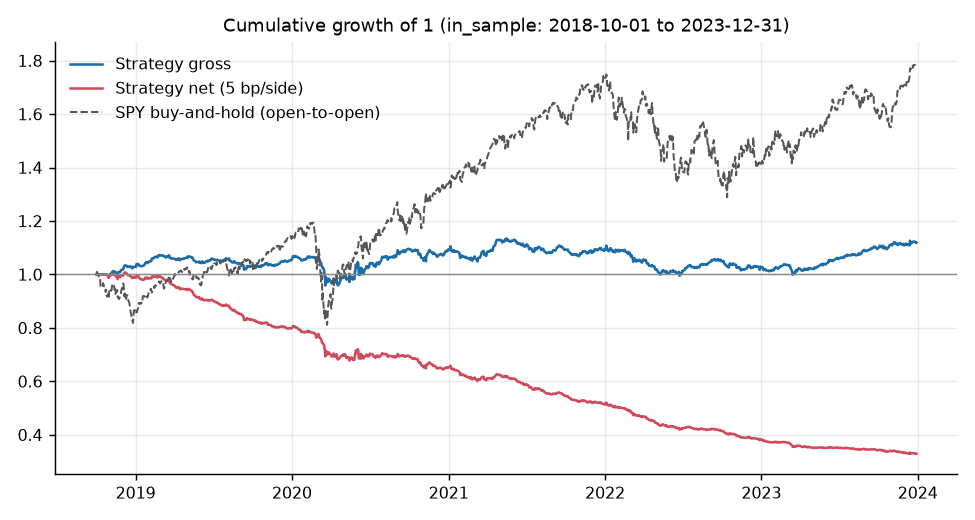

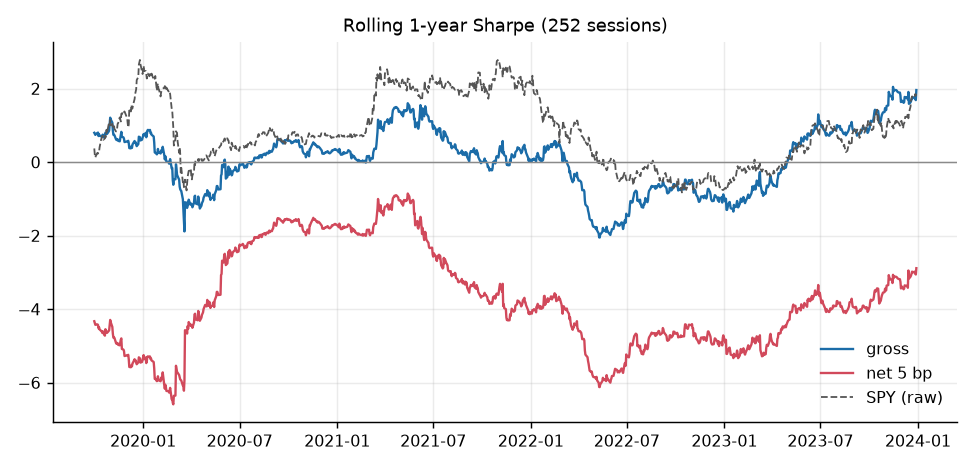

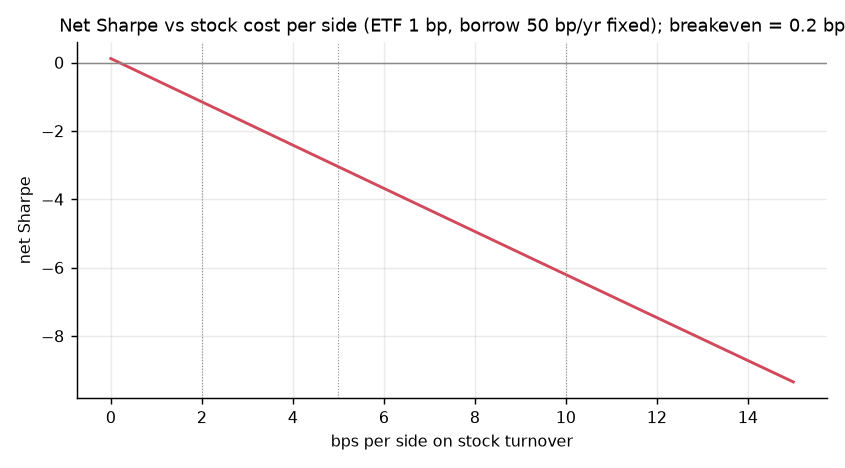

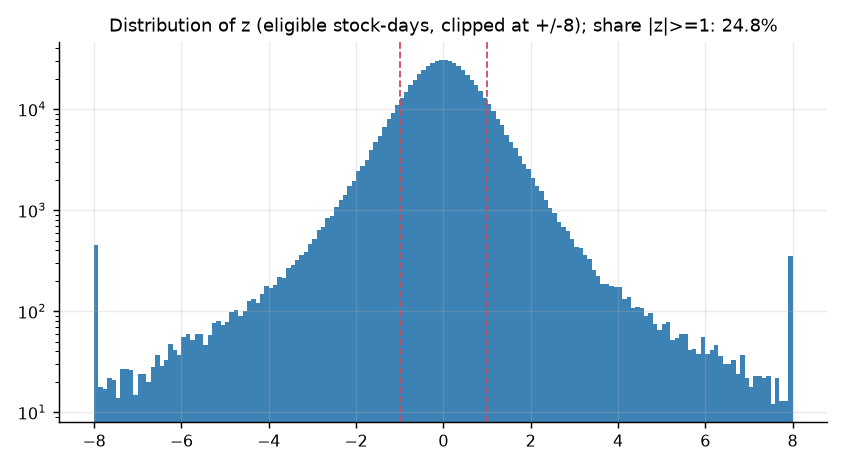

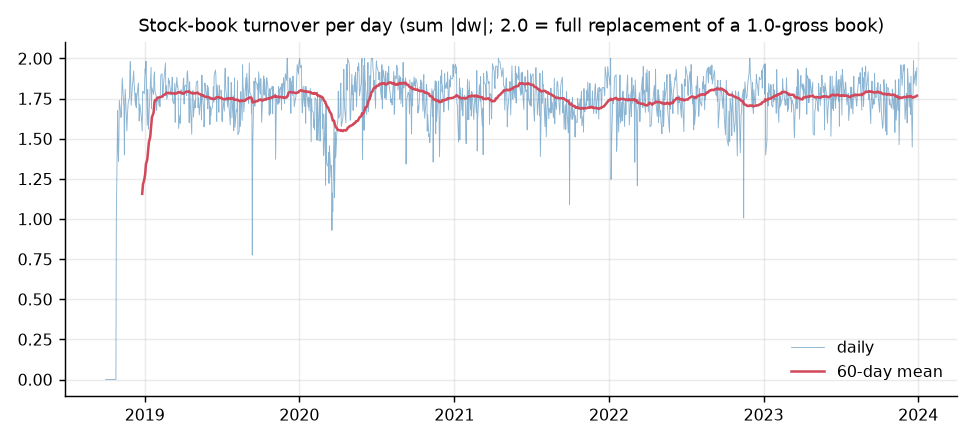

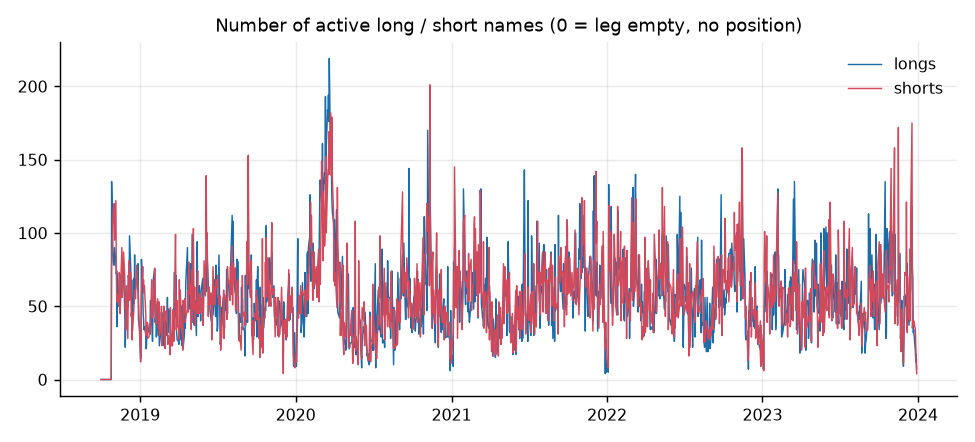

In [8]:
for f in sorted((RESULTS_DIR / 'figures').glob('is_fig*.png')):
    display(Image(filename=str(f)))

## Stage 3: holdout (run once)
`scripts/run_stage3_holdout.py --confirm` requires a frozen pre-registration (`results/FREEZE.json`, git tag `prereg-frozen`), writes `results/HOLDOUT_LOCK` and refuses to run again.

### VERDICT: **NOT SUPPORTED**

,holdout
period,holdout
start,2024-01-01
end,2026-09-30
n_days,689
fm_mean_coef,-0.00397
fm_nw_t,-0.655181
H1a,False
net5_sharpe,-4.015996
net5_sharpe_ci_lo,-5.377495
net5_sharpe_ci_hi,-2.748423


,strategy,cost_scenario,ann_return,ann_vol,sharpe,sharpe_ci_lo,sharpe_ci_hi,max_drawdown,turnover_daily,avg_long,avg_short,hit_rate,breakeven_bps_per_side,beta_spy,alpha_ann,alpha_nw_t
0,"PRIMARY open_open, sector-ETF hedge, |z|>=1, 1-day hold",gross,-0.015,0.063,-0.244,-1.466,0.964,-0.144,1.77,59.624,59.660,0.493,-0.707,0.029,-0.021,-0.526
1,"PRIMARY open_open, sector-ETF hedge, |z|>=1, 1-day hold",net_2bps,-0.121,0.063,-1.906,-3.143,-0.690,-0.328,1.77,59.624,59.660,0.436,-0.707,0.029,-0.127,-3.150
2,"PRIMARY open_open, sector-ETF hedge, |z|>=1, 1-day hold",net_5bps,-0.255,0.063,-4.016,-5.393,-2.754,-0.522,1.77,59.624,59.660,0.369,-0.707,0.029,-0.260,-6.499
3,"PRIMARY open_open, sector-ETF hedge, |z|>=1, 1-day hold",net_10bps,-0.478,0.063,-7.527,-9.219,-6.100,-0.730,1.77,59.624,59.660,0.275,-0.707,0.029,-0.483,-12.111
4,close_close_lag,gross,0.011,0.059,0.189,-0.864,1.249,-0.098,1.77,59.624,59.660,0.517,-0.113,-0.025,0.016,0.510
5,close_close_lag,net_2bps,-0.094,0.059,-1.601,-2.693,-0.533,-0.254,1.77,59.624,59.660,0.449,-0.113,-0.025,-0.089,-2.818
6,close_close_lag,net_5bps,-0.228,0.059,-3.872,-5.060,-2.744,-0.471,1.77,59.624,59.660,0.387,-0.113,-0.025,-0.223,-7.028
7,close_close_lag,net_10bps,-0.451,0.059,-7.646,-9.091,-6.301,-0.713,1.77,59.624,59.660,0.283,-0.113,-0.025,-0.446,-13.994
8,same_close [NON-TRADABLE UPPER BOUND],gross,0.008,0.064,0.127,-1.082,1.368,-0.144,1.77,59.673,59.699,0.509,-0.180,-0.000,0.008,0.208
9,same_close [NON-TRADABLE UPPER BOUND],net_2bps,-0.097,0.064,-1.527,-2.693,-0.375,-0.281,1.77,59.673,59.699,0.458,-0.180,-0.000,-0.097,-2.509


,regression,sector,mean_coef,nw_se,nw_t,n_days
0,close-to-close e(t+1) on e(t) [primary],ALL,-0.0040,0.0061,-0.6552,689
1,close-to-close e(t+1) on e(t) [primary],Information Technology,0.0019,0.0112,0.1663,689
2,close-to-close e(t+1) on e(t) [primary],Financials,-0.0264,0.0119,-2.2229,689
3,close-to-close e(t+1) on e(t) [primary],Energy,-0.0050,0.0140,-0.3565,689
4,close-to-close e(t+1) on e(t) [primary],Health Care,0.0026,0.0122,0.2115,689
5,close-to-close e(t+1) on e(t) [primary],Consumer Discretionary,-0.0015,0.0089,-0.1716,689
6,close-to-close e(t+1) on e(t) [primary],Consumer Staples,0.0075,0.0125,0.5991,689
7,close-to-close e(t+1) on e(t) [primary],Industrials,-0.0095,0.0088,-1.0795,689
8,close-to-close e(t+1) on e(t) [primary],Materials,-0.0047,0.0139,-0.3360,689
9,close-to-close e(t+1) on e(t) [primary],Utilities,-0.0371,0.0210,-1.7659,689


### Exploratory (holdout) -- not a basis for any claim

,strategy,cost_scenario,ann_return,ann_vol,sharpe,sharpe_ci_lo,sharpe_ci_hi,max_drawdown,turnover_daily,avg_long,avg_short,hit_rate,breakeven_bps_per_side,beta_spy,alpha_ann,alpha_nw_t
30,EXPLORATORY threshold 0.5,gross,0.006,0.049,0.127,-1.061,1.333,-0.071,1.530,130.382,128.938,0.501,-0.172,0.022,0.002,0.058
31,EXPLORATORY threshold 0.5,net_5bps,-0.199,0.049,-4.073,-5.532,-2.814,-0.433,1.530,130.382,128.938,0.361,-0.172,0.022,-0.204,-6.649
32,EXPLORATORY threshold 1.5,gross,-0.013,0.082,-0.158,-1.331,1.077,-0.206,1.870,26.936,27.234,0.501,-0.703,0.049,-0.023,-0.449
33,EXPLORATORY threshold 1.5,net_5bps,-0.269,0.082,-3.263,-4.509,-2.032,-0.565,1.870,26.936,27.234,0.403,-0.703,0.049,-0.279,-5.503
34,EXPLORATORY threshold 2,gross,0.030,0.113,0.264,-0.853,1.453,-0.192,1.867,13.314,13.195,0.525,0.096,0.086,0.013,0.187
35,EXPLORATORY threshold 2,net_5bps,-0.231,0.113,-2.036,-3.160,-0.917,-0.547,1.867,13.314,13.195,0.441,0.096,0.085,-0.248,-3.573
36,EXPLORATORY hold 2d (overlapping sleeves),gross,-0.010,0.045,-0.222,-1.286,0.870,-0.102,0.894,100.875,101.441,0.491,-0.861,0.048,-0.020,-0.781
37,EXPLORATORY hold 2d (overlapping sleeves),net_5bps,-0.132,0.045,-2.906,-4.028,-1.806,-0.326,0.894,100.875,101.441,0.411,-0.861,0.048,-0.142,-5.647
38,EXPLORATORY hold 3d (overlapping sleeves),gross,0.004,0.038,0.099,-0.932,1.185,-0.069,0.596,131.594,132.026,0.511,-0.200,0.044,-0.005,-0.234
39,EXPLORATORY hold 3d (overlapping sleeves),net_5bps,-0.078,0.038,-2.051,-3.129,-1.007,-0.212,0.596,131.594,132.026,0.437,-0.200,0.045,-0.087,-4.050


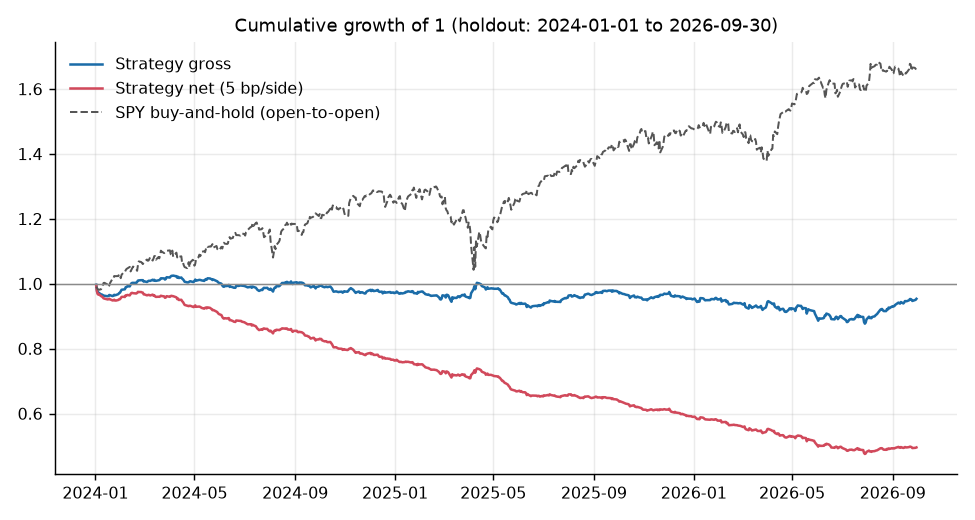

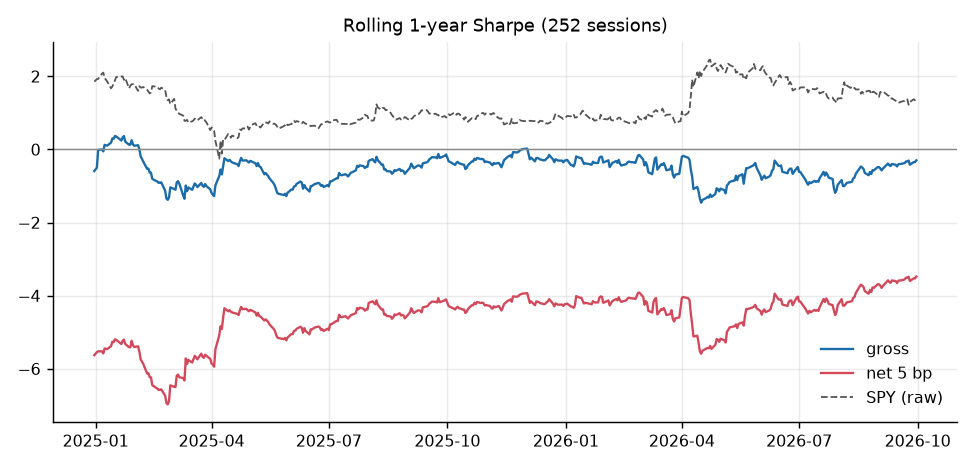

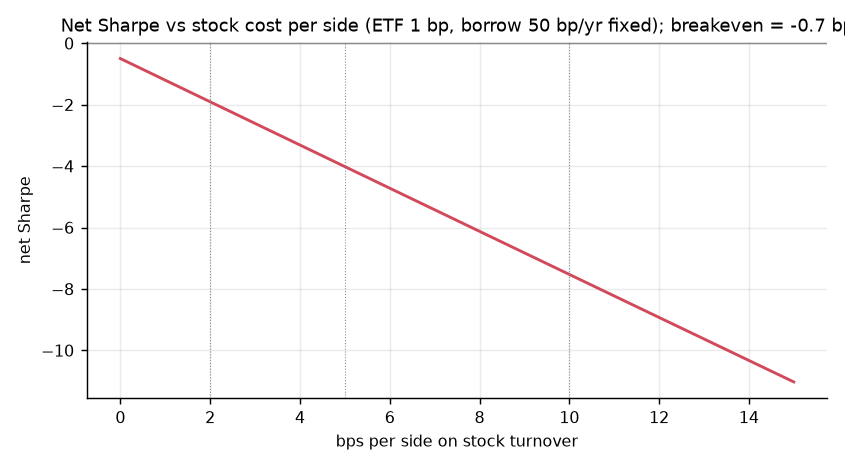

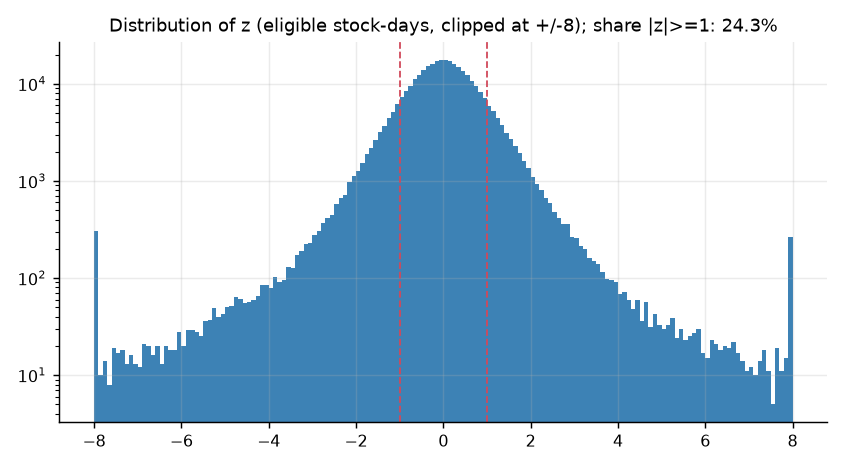

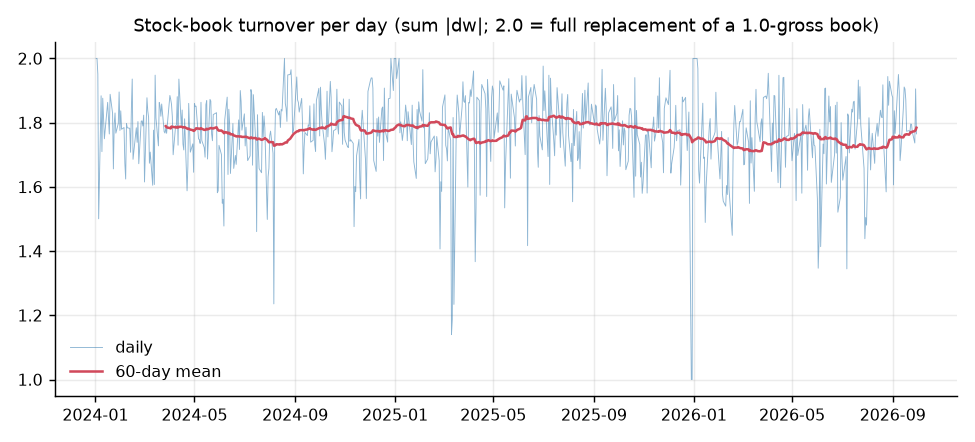

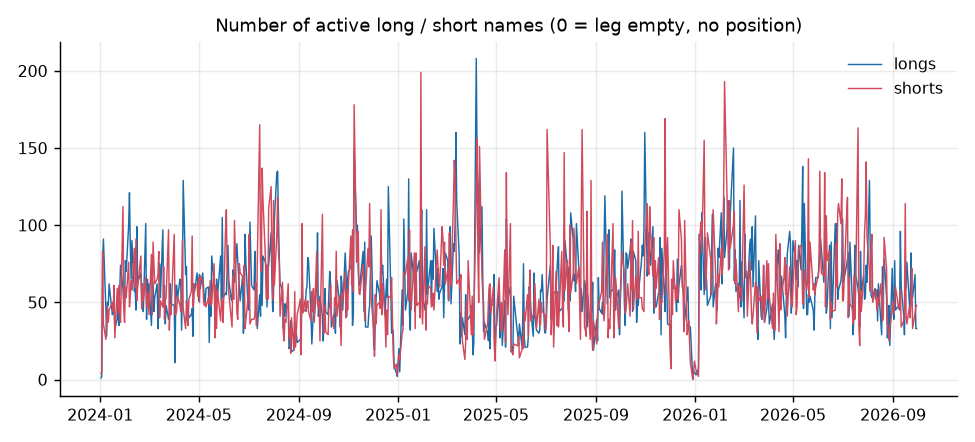

In [9]:
if (RESULTS_DIR / 'HOLDOUT_LOCK').exists() and (RESULTS_DIR / 'ho_decision_metrics.json').exists():
    d = json.loads((RESULTS_DIR / 'ho_decision_metrics.json').read_text())
    display(Markdown(f"### VERDICT: **{d['verdict']}**"))
    display(pd.Series(d).to_frame('holdout'))
    ht = pd.read_csv(RESULTS_DIR / 'ho_strategy_tables.csv')
    display(ht[ht.group.isin(['primary','variants','robustness','benchmark','benchmark_signal'])][cols].round(3))
    display(pd.read_csv(RESULTS_DIR / 'ho_fama_macbeth.csv').round(4))
    display(Markdown('### Exploratory (holdout) -- not a basis for any claim'))
    display(ht[ht.group == 'exploratory'][cols].round(3))
    for f in sorted((RESULTS_DIR / 'figures').glob('ho_fig*.png')):
        display(Image(filename=str(f)))
else:
    print('Holdout has not been run. Nothing to show.')

## Results pack

In [10]:
from src.results_pack import build_pack
display(Markdown(build_pack().read_text()[:3000] + '\n\n... (full text in results/results_pack.md)'))

# Results pack: ETF-hedged residual reversion (Holdout Research, strategy 03)

## 0. Verdict (holdout, run once)

**VERDICT: NOT SUPPORTED**  (H1a: fails; H1b: fails)

- H1a: holdout FM mean coefficient -0.0040, Newey-West t = -0.66 (needs negative and t < -2).
- H1b(i): net Sharpe at 5 bp/side = -4.02, 95% stationary-bootstrap CI [-5.38, -2.75] (needs CI entirely above 0).
- H1b(ii): alpha vs SPY = -0.260/yr, NW t = -6.50 (needs t > 2); beta 0.029.
- Gross Sharpe -0.24, CI [-1.46, 1.01].
- Non-gating: Sharpe difference vs SPY buy-and-hold (excess over T-bill) = -5.00, paired-bootstrap 95% CI [-6.95, -3.21]; breakeven cost = -0.71 bp/side; minimum detectable Sharpe for this holdout length = 1.19.

Net result: net Sharpe is NEGATIVE at 5 bp per side; the strategy lost money after costs.

## 1. Data summary and coverage

### Stage 0 report

Generated by `scripts/run_stage0_data.py`. Diagnostics cover **2018-06-01 to 2023-12-31 only**; holdout-period prices were split off at download and were not inspected (holdout checks run in Stage 3).

## Sources and conventions

- Prices: Yahoo Finance via `yfinance` (`auto_adjust=False`). `Close` is **split-adjusted but not dividend-adjusted** (true as-traded prices are not available from Yahoo); the $5 filter uses it, so stocks that later split may look cheaper than they were at the time. Returns use `Adj Close`; open-to-open uses `adj_open = Open*AdjClose/Close`.
- Universe: current S&P 500 list from Wikipedia (503 tickers) rolled back with the additions/removals table (https://en.wikipedia.org/wiki/Historical_components_of_the_S%26P_500; the table now lives on the 'Historical components' page, see DEVIATIONS.md). A change takes effect for the session on its effective date.
- Risk-free series for benchmark excess returns: `^IRX` (Yahoo 13-week T-bill yield).

## Survivorship bias

Survivorship bias is **reduced, not eliminated**. Removed stocks (acquired, bankrupt, shrunk) are far less likely than survivors to have Yahoo price history or a Yahoo sector label, so the usable universe is tilted towards survivors. The coverage table below quantifies this by year.

## Coverage by calendar year (average over sessions)

| year | (a) PIT members | (b) with price data | (c) with sector label | (d) usable for trading | flag |
|---|---|---|---|---|---|
| 2018 | 508.0 | 86.0% | 87.6% | 86.0% | **<90%** |
| 2019 | 506.4 | 88.0% | 89.2% | 88.0% | **<90%** |
| 2020 | 506.0 | 90.3% | 91.1% | 90.3% |  |
| 2021 | 506.0 | 91.8% | 92.6% | 91.8% |  |
| 2022 | 504.7 | 93.8% | 94.7% | 93.8% |  |
| 2023 | 504.0 | 95.6% | 96.5% | 95.6% |  |
| 2024 | 504.0 | deferred to Stage 3 | 97.3% | deferred to Stage 3 |  |
| 2025 | 504.0 | deferred to Stage 3 | 98.3% | deferred to Stage 3 |  |
| 2026 | 504.0 | deferred to Stage 3 | 99.6% | deferred to Stage 3 |  |

(b) and (d) for holdout years need holdout prices and are filled in by Stage 3.

## Excluded / problem tickers (point-in-time members during the in-sample window)

- Members in-sampl

... (full text in results/results_pack.md)